# NHANES 1999–2004: 항핵항체(ANA) 양성 예측 모델

**목표**: 인구학·생활습관·임상 변수로 **ANA 양성(자가면역 전단계 신호)**을 예측하는 모델을 만들고, 어떤 요인이 예측에 기여하는지 확인합니다.

**데이터**: 미국 NHANES 1999–2004 ANA 하위표본 (`SSANA_A`, 약 4,500명, 12세 이상)
- ANA는 HEp-2 간접면역형광법으로 측정, 염색 강도 0~4로 기록됩니다.
- 선행연구(Satoh 2012, Dinse 2018 등)와 같이 **핵 염색 강도 ≥3을 양성**으로 정의합니다.

**구성**
1. 데이터 다운로드 및 병합
2. 변수 정의 및 전처리
3. 기술통계 (가중 유병률)
4. 연관성 분석 (가중 로지스틱 회귀)
5. 예측 모델 (로지스틱 회귀 / 랜덤포레스트 / 그래디언트 부스팅)
6. 성능 평가 (ROC-AUC, PR-AUC, 보정, 하위군)
7. 변수 중요도
8. 해석과 한계

**주의할 점**
- 횡단면 자료이므로 "미래 발생"이 아니라 **현재 ANA 상태 분류**입니다.
- ANA 하위표본 전용 가중치 `WTANA6YR`은 6년(3주기)을 **함께** 분석할 때만 유효합니다.
- ANA 패턴·특이항체 변수(SSNU*, SSU1RNP 등)는 결과에서 파생된 값이므로 **특성으로 쓰면 데이터 누수**가 됩니다.

In [15]:
# 필요 패키지: pandas, numpy, scikit-learn, matplotlib (statsmodels는 선택)
# !pip install pandas numpy scikit-learn matplotlib statsmodels

!pip install koreanize-matplotlib
import os, io, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
SEED = 42
np.random.seed(SEED)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 18.2 MB/s  0:00:00


## 1. 설정

In [2]:
DATA_DIR = "nhanes_data"          # 다운로드한 XPT 파일 저장 폴더
os.makedirs(DATA_DIR, exist_ok=True)

# 인터넷 없이 코드 흐름만 확인하고 싶으면 True (가상 데이터 사용, 결과 해석 금지)
USE_SYNTHETIC = os.environ.get("ANA_SYNTHETIC", "0") == "1"

MIN_AGE = 20   # 흡연·교육 변수가 20세 이상에서 수집되어 성인으로 제한

# 주기별 파일명 (1999-2000은 접미사 없음)
CYCLES = {
    "1999-2000": {"start": 1999, "DEMO": "DEMO",   "BMX": "BMX",   "SMQ": "SMQ",   "MCQ": "MCQ",   "CRP": "LAB11"},
    "2001-2002": {"start": 2001, "DEMO": "DEMO_B", "BMX": "BMX_B", "SMQ": "SMQ_B", "MCQ": "MCQ_B", "CRP": "L11_B"},
    "2003-2004": {"start": 2003, "DEMO": "DEMO_C", "BMX": "BMX_C", "SMQ": "SMQ_C", "MCQ": "MCQ_C", "CRP": "L11_C"},
}
ANA_FILE = ("SSANA_A", 1999)      # 6년 통합 ANA 파일 (1999 폴더에 있음)

## 2. 데이터 다운로드 및 병합

In [3]:
def _urls(name, start):
    end = start + 1
    return [
        f"https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{start}/DataFiles/{name}.xpt",
        f"https://wwwn.cdc.gov/Nchs/Nhanes/{start}-{end}/{name}.XPT",
    ]

def load_xpt(name, start, required=True):
    # 로컬에 있으면 재사용, 없으면 CDC에서 다운로드
    path = os.path.join(DATA_DIR, f"{name}.xpt")
    if not os.path.exists(path):
        last_err = None
        for url in _urls(name, start):
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=120) as r:
                    data = r.read()
                if data[:6] != b"HEADER":       # XPT가 아니라 HTML 오류 페이지인 경우
                    raise ValueError("XPT 형식이 아님")
                with open(path, "wb") as f:
                    f.write(data)
                break
            except Exception as e:
                last_err = e
        else:
            msg = f"[{name}] 다운로드 실패: {last_err}  → CDC 사이트에서 직접 받아 {DATA_DIR}/ 에 넣어주세요."
            if required:
                raise RuntimeError(msg)
            print("경고:", msg)
            return None
    df = pd.read_sas(path, format="xport")
    df["SEQN"] = df["SEQN"].astype(int)
    return df


def make_synthetic_raw(n=4500, seed=SEED):
    # 실제 파일과 같은 변수명을 가진 가상 데이터 (코드 검증용)
    rng = np.random.default_rng(seed)
    seqn = np.arange(1, n + 1)
    sex = rng.integers(1, 3, n); age = rng.integers(12, 86, n)
    race = rng.choice([1, 2, 3, 4, 5], n, p=[.25, .05, .45, .2, .05])
    bmi = rng.normal(28, 6, n).clip(15, 60)
    logit = -3.2 + 0.9 * (sex == 2) + 0.025 * (age - 40) + 0.3 * (race == 4) - 0.02 * (bmi - 28)
    ana = rng.random(n) < 1 / (1 + np.exp(-logit))
    ssnuc = np.where(ana, rng.choice([3, 4], n), rng.choice([0, 1, 2], n, p=[.6, .3, .1]))
    raw = {
        "ANA": pd.DataFrame({"SEQN": seqn, "WTANA6YR": rng.uniform(2e3, 2e5, n), "SSNUC": ssnuc,
                             "SSTOT": ssnuc, "SSCYT": rng.choice([0, 1, 2], n)}),
        "DEMO": pd.DataFrame({"SEQN": seqn, "RIAGENDR": sex, "RIDAGEYR": age, "RIDRETH1": race,
                              "INDFMPIR": rng.uniform(0, 5, n), "DMDEDUC2": rng.choice([1, 2, 3, 4, 5, 9], n),
                              "RIDEXPRG": rng.choice([1, 2, np.nan], n, p=[.02, .3, .68]),
                              "SDMVSTRA": rng.integers(1, 40, n), "SDMVPSU": rng.integers(1, 3, n)}),
        "BMX": pd.DataFrame({"SEQN": seqn, "BMXBMI": bmi}),
        "SMQ": pd.DataFrame({"SEQN": seqn, "SMQ020": rng.choice([1, 2, 9], n, p=[.45, .54, .01]),
                             "SMQ040": rng.choice([1, 2, 3], n)}),
        "MCQ": pd.DataFrame({"SEQN": seqn, "MCQ160A": rng.choice([1, 2, 9], n, p=[.2, .79, .01]),
                             "MCQ190": rng.choice([1, 2, 3, np.nan], n, p=[.05, .1, .05, .8]),
                             "MCQ160M": rng.choice([1, 2], n, p=[.1, .9])}),
        "CRP": pd.DataFrame({"SEQN": seqn, "LBXCRP": rng.lognormal(-1.5, 1.0, n)}),
    }
    return raw


def load_all():
    if USE_SYNTHETIC:
        print("⚠️ 가상 데이터 모드입니다. 결과를 해석하지 마세요.")
        return make_synthetic_raw()
    raw = {"ANA": load_xpt(*ANA_FILE)}
    for comp, required in [("DEMO", True), ("BMX", True), ("SMQ", True), ("MCQ", False), ("CRP", False)]:
        parts = []
        for cyc, info in CYCLES.items():
            d = load_xpt(info[comp], info["start"], required=required)
            if d is not None:
                d["CYCLE"] = cyc
                parts.append(d)
        raw[comp] = pd.concat(parts, ignore_index=True) if parts else None
    return raw

raw = load_all()
for k, v in raw.items():
    print(f"{k:5s}", "없음" if v is None else v.shape)

ANA   (4532, 70)
DEMO  (31126, 155)
BMX   (29402, 46)
SMQ   (15332, 46)
MCQ   (29608, 184)
CRP   (26785, 11)


## 3. 변수 정의

| 변수 | 출처 | 정의 |
|---|---|---|
| `ana_pos` (결과) | SSANA_A `SSNUC` | 핵 염색 강도 ≥3 → 1 |
| `age`, `female`, `race` | DEMO | 연령, 성별, 인종/민족 (RIDRETH1) |
| `pir` | DEMO `INDFMPIR` | 가구소득/빈곤선 비율 |
| `educ` | DEMO `DMDEDUC2` | 교육수준 (20세 이상) |
| `bmi` | BMX `BMXBMI` | 체질량지수 |
| `smoking` | SMQ `SMQ020`, `SMQ040` | 비흡연 / 과거흡연 / 현재흡연 |
| `log_crp` | LAB11 / L11 `LBXCRP` | log(CRP mg/dL) — 전신 염증 지표 |
| `arthritis`, `self_ra`, `thyroid` | MCQ | 의사진단 관절염, 자가보고 RA, 갑상선 질환 |

NHANES 코드 7/9/77/99(거부·모름)는 결측으로 처리합니다. 임신부는 제외합니다.

In [4]:
def nhanes_na(s, codes=(7, 9, 77, 99, 777, 999)):
    return s.where(~s.isin(codes))

df = raw["ANA"][["SEQN", "WTANA6YR", "SSNUC", "SSTOT"]].copy()
demo_cols = ["SEQN", "RIAGENDR", "RIDAGEYR", "RIDRETH1", "INDFMPIR", "DMDEDUC2",
             "RIDEXPRG", "SDMVSTRA", "SDMVPSU"]
df = df.merge(raw["DEMO"][[c for c in demo_cols if c in raw["DEMO"]]], on="SEQN", how="left")
df = df.merge(raw["BMX"][["SEQN", "BMXBMI"]], on="SEQN", how="left")
df = df.merge(raw["SMQ"][["SEQN", "SMQ020", "SMQ040"]], on="SEQN", how="left")
if raw.get("MCQ") is not None:
    mcq_cols = [c for c in ["SEQN", "MCQ160A", "MCQ190", "MCQ160M"] if c in raw["MCQ"]]
    df = df.merge(raw["MCQ"][mcq_cols], on="SEQN", how="left")
if raw.get("CRP") is not None:
    df = df.merge(raw["CRP"][["SEQN", "LBXCRP"]], on="SEQN", how="left")

# --- 결과 변수 ---
df["ana_pos"] = (df["SSNUC"] >= 3).astype(int)

# --- 인구학 ---
df["age"] = df["RIDAGEYR"]
df["female"] = (df["RIAGENDR"] == 2).astype(int)
race_map = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 5: "Other"}
df["race"] = df["RIDRETH1"].map(race_map)
df["pir"] = df["INDFMPIR"]
educ_map = {1: "<HS", 2: "<HS", 3: "HS", 4: "Some college", 5: "College+"}
df["educ"] = nhanes_na(df["DMDEDUC2"]).map(educ_map)

# --- 신체·생활습관 ---
df["bmi"] = df["BMXBMI"]
smq020, smq040 = nhanes_na(df["SMQ020"]), nhanes_na(df["SMQ040"])
df["smoking"] = np.select(
    [smq020 == 2, (smq020 == 1) & smq040.isin([1, 2]), (smq020 == 1) & (smq040 == 3)],
    ["Never", "Current", "Former"], default=None)
df["smoking"] = df["smoking"].replace({None: np.nan})

# --- 염증 지표 ---
if "LBXCRP" in df:
    df["log_crp"] = np.log(df["LBXCRP"].clip(lower=0.01))

# --- 동반질환 (있을 때만) ---
if "MCQ160A" in df:
    df["arthritis"] = nhanes_na(df["MCQ160A"]).map({1: 1, 2: 0})
if "MCQ190" in df:
    df["self_ra"] = np.where(df["MCQ160A"] == 1, (nhanes_na(df["MCQ190"]) == 1).astype(float), 0.0)
    df.loc[nhanes_na(df["MCQ160A"]).isna(), "self_ra"] = np.nan
if "MCQ160M" in df:
    df["thyroid"] = nhanes_na(df["MCQ160M"]).map({1: 1, 2: 0})

# --- 분석 대상 ---
n0 = len(df)
df = df[df["age"] >= MIN_AGE]
df = df[df["RIDEXPRG"] != 1]          # 임신부 제외
df = df[df["WTANA6YR"] > 0]
print(f"전체 {n0} → 분석 대상 {len(df)}명 (≥{MIN_AGE}세, 비임신)")
print(f"ANA 양성: {df['ana_pos'].sum()}명 ({df['ana_pos'].mean():.1%}, 비가중)")

NUM_FEATS = [c for c in ["age", "pir", "bmi", "log_crp"] if c in df]
BIN_FEATS = [c for c in ["female", "arthritis", "self_ra", "thyroid"] if c in df]
CAT_FEATS = ["race", "educ", "smoking"]
FEATURES = NUM_FEATS + BIN_FEATS + CAT_FEATS
print("특성:", FEATURES)
df[FEATURES].isna().mean().round(3).to_frame("결측 비율").T

전체 4532 → 분석 대상 3242명 (≥20세, 비임신)
ANA 양성: 394명 (12.2%, 비가중)
특성: ['age', 'pir', 'bmi', 'log_crp', 'female', 'arthritis', 'self_ra', 'thyroid', 'race', 'educ', 'smoking']


,age,pir,bmi,log_crp,female,arthritis,self_ra,thyroid,race,educ,smoking
결측 비율,0.0,0.076,0.029,0.0,0.0,0.001,0.001,0.647,0.0,0.002,0.001


## 4. 기술통계 — 가중 ANA 유병률

In [5]:
def wprev(g):
    return pd.Series({"N": len(g),
                      "양성 수": int(g["ana_pos"].sum()),
                      "가중 유병률(%)": 100 * np.average(g["ana_pos"], weights=g["WTANA6YR"])})

df["age_grp"] = pd.cut(df["age"], [19, 39, 59, 120], labels=["20-39", "40-59", "60+"])
print("전체 가중 유병률: %.1f%%" % (100 * np.average(df["ana_pos"], weights=df["WTANA6YR"])))
tables = {v: df.groupby(v, observed=True).apply(wprev) for v in ["female", "age_grp", "race", "smoking"]}
pd.concat(tables, names=["변수", "수준"]).round(1)

전체 가중 유병률: 12.2%


N   양성 수  가중 유병률(%)
변수      수준                                        
female  0                 1625.0  146.0        8.1
        1                 1617.0  248.0       16.1
age_grp 20-39             1083.0  136.0       12.2
        40-59             1017.0  115.0       11.5
        60+               1142.0  143.0       13.5
race    Mexican American   700.0   77.0       11.2
        NH Black           564.0   76.0       13.6
        NH White          1702.0  211.0       12.5
        Other              125.0    8.0        5.2
        Other Hispanic     151.0   22.0       14.2
smoking Current            742.0   76.0       10.0
        Former             891.0  105.0       11.6
        Never             1606.0  212.0       13.6

## 5. 연관성 분석 — 가중 로지스틱 회귀

예측 모델에 앞서, 각 요인과 ANA 양성의 **보정된 연관성(OR)**을 봅니다.
가중치를 평균 1로 정규화해 사용합니다. 층·집락(SDMVSTRA/SDMVPSU)을 반영한 정확한 분산 추정은 R의 `survey` 패키지를 권장하며, 여기서의 신뢰구간은 근사치입니다.

In [6]:
X_or = pd.get_dummies(df[FEATURES], columns=CAT_FEATS, drop_first=True, dtype=float)
X_or = X_or.fillna(X_or.median())      # 연관성 분석용 단순 대치 (예측 모델은 파이프라인 내 대치)
X_or["age_per10"] = X_or.pop("age") / 10
w = df["WTANA6YR"] / df["WTANA6YR"].mean()

try:
    import statsmodels.api as sm
    glm = sm.GLM(df["ana_pos"], sm.add_constant(X_or), family=sm.families.Binomial(), var_weights=w).fit()
    or_table = pd.DataFrame({"OR": np.exp(glm.params), "95% CI 하한": np.exp(glm.conf_int()[0]),
                             "95% CI 상한": np.exp(glm.conf_int()[1]), "p": glm.pvalues}).drop("const")
except ImportError:
    lr = LogisticRegression(C=1e6, max_iter=5000).fit(X_or, df["ana_pos"], sample_weight=w)
    or_table = pd.DataFrame({"OR": np.exp(lr.coef_[0])}, index=X_or.columns)
    print("statsmodels가 없어 OR만 표시합니다 (pip install statsmodels).")
or_table.round(3)

,OR,95% CI 하한,95% CI 상한,p
pir,1.006,0.931,1.088,0.877
bmi,0.974,0.954,0.995,0.016
log_crp,0.997,0.904,1.099,0.950
female,2.065,1.638,2.602,0.000
arthritis,1.092,0.811,1.469,0.563
self_ra,1.269,0.745,2.162,0.381
thyroid,1.817,1.150,2.870,0.010
race_NH Black,1.241,0.731,2.107,0.424
race_NH White,1.096,0.688,1.747,0.699
race_Other,0.397,0.176,0.898,0.026


## 6. 예측 모델

- 학습 80% / 테스트 20% (층화 분할)
- 결측 대치·표준화·원-핫 인코딩을 **파이프라인 안에** 넣어 테스트 정보가 학습에 새지 않게 합니다.
- 클래스 불균형(양성 약 10~15%)이 있으므로 정확도 대신 **ROC-AUC와 PR-AUC**로 평가합니다.
- 학습 시 `class_weight="balanced"`를 사용합니다. 이 경우 예측 확률이 실제보다 높게 나오므로, 보정 곡선은 이 점을 감안해 해석합니다.

In [7]:
X, y, wt = df[FEATURES], df["ana_pos"].values, df["WTANA6YR"].values
X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(
    X, y, wt, test_size=0.2, stratify=y, random_state=SEED)

def preprocessor(scale=True):
    num = Pipeline([("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else []))
    binp = Pipeline([("imp", SimpleImputer(strategy="most_frequent"))])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_FEATS), ("bin", binp, BIN_FEATS), ("cat", cat, CAT_FEATS)])

models = {
    "Logistic": Pipeline([("pre", preprocessor()),
                          ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "RandomForest": Pipeline([("pre", preprocessor(scale=False)),
                              ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=20,
                                                             class_weight="balanced", n_jobs=-1,
                                                             random_state=SEED))]),
    "HistGB": Pipeline([("pre", preprocessor(scale=False)),
                        ("clf", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                               max_iter=300, class_weight="balanced",
                                                               random_state=SEED))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_res = {}
for name, m in models.items():
    s = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc")
    cv_res[name] = s
    print(f"{name:13s} 5-fold CV ROC-AUC = {s.mean():.3f} ± {s.std():.3f}")

Logistic      5-fold CV ROC-AUC = 0.572 ± 0.044
RandomForest  5-fold CV ROC-AUC = 0.558 ± 0.030
HistGB        5-fold CV ROC-AUC = 0.547 ± 0.024


## 7. 테스트셋 평가

In [8]:
def bootstrap_ci(y, p, metric, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        vals.append(metric(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

preds, rows = {}, []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    preds[name] = p
    lo, hi = bootstrap_ci(y_te, p, roc_auc_score)
    rows.append({"모델": name,
                 "ROC-AUC": roc_auc_score(y_te, p), "95% CI": f"{lo:.3f}–{hi:.3f}",
                 "ROC-AUC(가중)": roc_auc_score(y_te, p, sample_weight=w_te),
                 "PR-AUC": average_precision_score(y_te, p),
                 "PR-AUC 기준선(유병률)": y_te.mean(),
                 "Brier": brier_score_loss(y_te, p)})
results = pd.DataFrame(rows).set_index("모델").round(3)
results

,ROC-AUC,95% CI,ROC-AUC(가중),PR-AUC,PR-AUC 기준선(유병률),Brier
모델,,,,,,
Logistic,0.603,0.541–0.665,0.609,0.148,0.122,0.239
RandomForest,0.595,0.533–0.658,0.598,0.148,0.122,0.190
HistGB,0.550,0.479–0.619,0.570,0.137,0.122,0.201


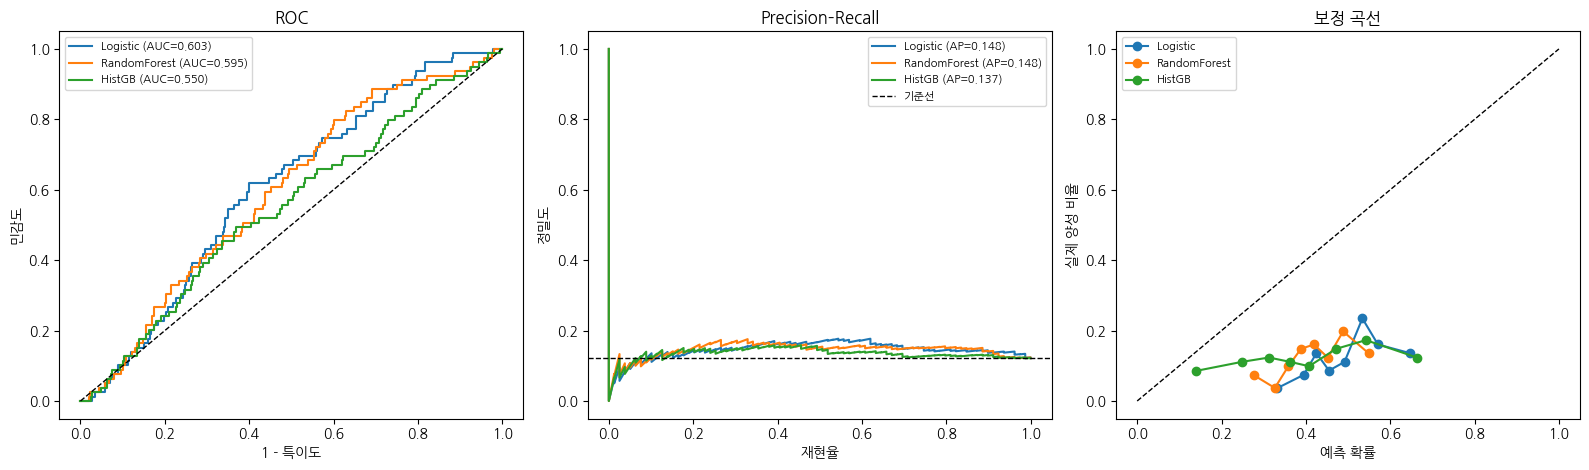

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for name, p in preds.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_te, p):.3f})")
    frac, mean_p = calibration_curve(y_te, p, n_bins=8, strategy="quantile")
    axes[2].plot(mean_p, frac, "o-", label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(xlabel="1 - 특이도", ylabel="민감도", title="ROC")
axes[1].axhline(y_te.mean(), color="k", ls="--", lw=1, label="기준선")
axes[1].set(xlabel="재현율", ylabel="정밀도", title="Precision–Recall")
axes[2].plot([0, 1], [0, 1], "k--", lw=1); axes[2].set(xlabel="예측 확률", ylabel="실제 양성 비율", title="보정 곡선")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
# 한글이 깨지면: plt.rcParams["font.family"] = "AppleGothic"(Mac) / "Malgun Gothic"(Windows)

### 고위험군 선별 관점

실제 선별에서는 "상위 X%를 고위험군으로 뽑았을 때 양성을 얼마나 잡는가"가 중요합니다.

In [10]:
best = results["ROC-AUC"].idxmax()
p = preds[best]
rows = []
for top in [0.1, 0.2, 0.3, 0.5]:
    thr = np.quantile(p, 1 - top)
    sel = p >= thr
    tp = (sel & (y_te == 1)).sum()
    rows.append({"상위 비율": f"{int(top*100)}%", "선별 인원": sel.sum(),
                 "민감도(양성 포착률)": tp / y_te.sum(), "양성예측도(PPV)": tp / sel.sum(),
                 "PPV / 유병률 (lift)": (tp / sel.sum()) / y_te.mean()})
print(f"최고 모델: {best}")
pd.DataFrame(rows).set_index("상위 비율").round(3)

최고 모델: Logistic


,선별 인원,민감도(양성 포착률),양성예측도(PPV),PPV / 유병률 (lift)
상위 비율,,,,
10%,65,0.101,0.123,1.011
20%,130,0.228,0.138,1.137
30%,195,0.405,0.164,1.348
50%,325,0.658,0.160,1.314


### 하위군 성능 (성별·연령)

In [11]:
te = X_te.copy(); te["y"] = y_te; te["p"] = preds[best]
te["age_grp"] = pd.cut(te["age"], [19, 39, 59, 120], labels=["20-39", "40-59", "60+"])
sub = []
for col in ["female", "age_grp"]:
    for lvl, g in te.groupby(col, observed=True):
        if g["y"].nunique() == 2 and g["y"].sum() >= 10:
            sub.append({"하위군": f"{col}={lvl}", "N": len(g), "양성": int(g["y"].sum()),
                        "ROC-AUC": roc_auc_score(g["y"], g["p"])})
pd.DataFrame(sub).set_index("하위군").round(3)

,N,양성,ROC-AUC
하위군,,,
female=0,326,25,0.589
female=1,323,54,0.471
age_grp=20-39,237,24,0.645
age_grp=40-59,189,26,0.573
age_grp=60+,223,29,0.604


## 8. 변수 중요도 (순열 중요도, 테스트셋 기준)

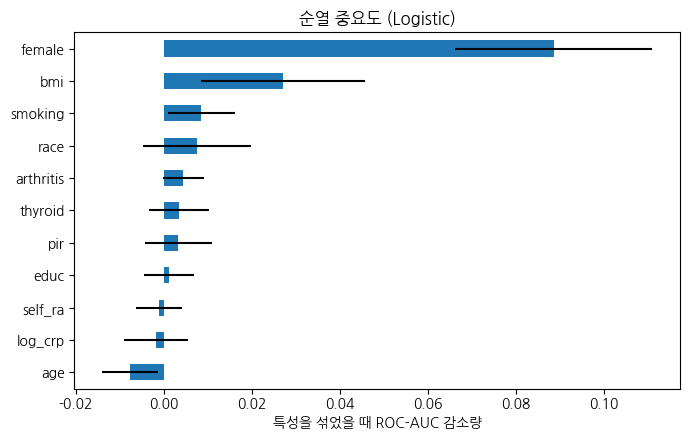

,평균 AUC 감소,표준편차
female,0.0887,0.0225
bmi,0.0272,0.0186
smoking,0.0086,0.0076
race,0.0076,0.0122
arthritis,0.0045,0.0046
thyroid,0.0036,0.0068
pir,0.0034,0.0077
educ,0.0012,0.0057
self_ra,-0.0011,0.0052
log_crp,-0.0017,0.0072


In [17]:
pi = permutation_importance(models[best], X_te, y_te, scoring="roc_auc",
                            n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"평균 AUC 감소": pi.importances_mean, "표준편차": pi.importances_std},
                   index=FEATURES).sort_values("평균 AUC 감소")
imp.plot.barh(y="평균 AUC 감소", xerr="표준편차", legend=False, figsize=(7, 4.5),
              title=f"순열 중요도 ({best})")
plt.xlabel("특성을 섞었을 때 ROC-AUC 감소량"); plt.tight_layout(); plt.show()
imp.sort_values("평균 AUC 감소", ascending=False).round(4)

## 9. 해석 가이드와 한계

**결과를 읽는 법**
- ANA 양성은 여성·고령에서 많다는 것이 알려져 있어, **성별과 연령만으로도 AUC 0.6 안팎**이 나올 수 있습니다. 다른 변수가 이 기준선보다 얼마나 더하는지가 핵심입니다.
  → 추천 실험: `FEATURES = ["age", "female"]`만 쓴 기준 모델과 비교 (ΔAUC).
- PR-AUC는 유병률(기준선) 대비 몇 배인지로 해석합니다.
- 4절의 연관성(OR)과 8절의 예측 기여도는 **다른 질문**입니다. 연관이 있어도 예측력은 작을 수 있습니다.

**한계**
- 횡단면 자료 → 인과나 "향후 발생" 예측이 아닙니다.
- ANA 양성 ≠ 자가면역질환. 건강한 사람도 상당수 양성입니다.
- 자가보고 질환 변수는 오분류 가능성이 있습니다.
- 가중 분석은 근사치이며, 정식 복합표본 분석은 R `survey` 패키지를 권장합니다.
- 외부 검증 데이터가 없습니다 (가능하면 NHANES 2011–2012 ANA 자료로 시간적 외부 검증).

**확장 아이디어**
1. 특성 추가: 혈중 비타민 D, 백혈구 수, 갑상선 호르몬, 환경 노출(유기염소계, 수은 — ANA 하위표본이 다이옥신 하위표본에서 뽑힘)
2. 결과 확장: ANA 패턴별(균질형·반점형) 또는 특이항체(항Ro/SSA 등) 예측
3. 시간적 외부 검증: 2011–2012 ANA 자료
4. 사망 연계(NDI) 자료로 ANA 양성과 생존 분석